In [1]:
from dotenv import load_dotenv
import os
import guidance
from guidance import models
import pandas as pd
import numpy as np
import causallearn
from causallearn.search.ConstraintBased.PC import pc
import seaborn as sns

import pydot
from causallearn.graph.Edge import Edge
from causallearn.graph.Edges import Edges
from causallearn.graph.Endpoint import Endpoint
from causallearn.graph.Graph import Graph
from causallearn.graph.Node import Node
from causallearn.graph.NodeType import NodeType
from causallearn.graph.GraphNode import GraphNode
from causallearn.utils.PCUtils.BackgroundKnowledge import BackgroundKnowledge

In [31]:
#pywhyllm imports
from pywhyllm import ModelType, RelationshipStrategy
model_type = ModelType.Completion
relationship_strategy = RelationshipStrategy.Parent
from utils import pywhyllm_edges_to_causal_graph

In [21]:
load_dotenv()
openai_api_key = os.getenv("OPENAI_API_KEY")

DATA

In [4]:
data_obs=pd.read_parquet("data/FINAL_PUBLIC_observed.parquet")
data_exp=pd.read_parquet("data/FINAL_PUBLIC_experimental.parquet")

In [5]:
data_obs.head()

,Outcome_Binary,Outcome_Continuous,New_Feature,Device_Spec_A,Total_Device_Usage,Browser_1_Usage,Browser_2_Usage,Browser_3_Usage,Browser_4_Usage,Other_Browser_Usage,...,Manufacturer_2,Manufacturer_3,Manufacturer_4,Manufacturer_5,Manufacturer_6,Device_Spec_B_1,Device_Spec_B_2,Device_Spec_C_1,Device_Spec_C_2,Device_Spec_C_3
0,0,3.0,True,True,222770.248,0.000,211742.529,0.0,0.000,0.0,...,True,False,False,False,False,False,True,False,True,False
1,0,4.0,True,False,63428.349,0.000,46382.551,0.0,10.281,0.0,...,False,False,True,False,False,True,False,False,True,False
2,1,11.0,True,True,98237.129,48.032,59105.369,0.0,0.000,0.0,...,False,False,True,False,False,False,True,False,True,False
3,1,28.0,True,True,151536.273,4260.423,68922.476,0.0,0.000,0.0,...,False,True,False,False,False,False,True,False,True,False
4,1,0.0,True,True,100655.885,30042.437,52609.590,0.0,0.000,0.0,...,False,True,False,False,False,False,True,False,True,False


In [13]:
data_obs=data_obs.drop(columns=["Outcome_Continuous"])

In [6]:
data_obs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445286 entries, 0 to 445285
Data columns (total 44 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   Outcome_Binary                    445286 non-null  int64  
 1   Outcome_Continuous                445286 non-null  float64
 2   New_Feature                       445286 non-null  bool   
 3   Device_Spec_A                     445286 non-null  bool   
 4   Total_Device_Usage                445286 non-null  float64
 5   Browser_1_Usage                   445286 non-null  float64
 6   Browser_2_Usage                   445286 non-null  float64
 7   Browser_3_Usage                   445286 non-null  float64
 8   Browser_4_Usage                   445286 non-null  float64
 9   Other_Browser_Usage               445286 non-null  float64
 10  EngagementSegment_General         445286 non-null  bool   
 11  EngagementSegment_Highly Engaged  445286 non-null  b

DISCOVERY - CAUSALLEARN

In [14]:
input_df = data_obs.copy()

# causal-learn takes a plain (n, d) numeric array where ONE COLUMN == ONE NODE, and has no encoding layer of its own. 
ONE_HOT_BLOCKS = {
    "EngagementSegment": "EngagementSegment_",
    "A14Region": "A14Region_",
    "AppCategoryCohort": "AppCategoryCohort_",
    "Manufacturer": "Manufacturer_",
    "Device_Spec_B": "Device_Spec_B_",
    "Device_Spec_C": "Device_Spec_C_",
}

REFERENCE_LEVEL = "__reference__"


def collapse_one_hot(df, prefix, name):
    """Invert a one-hot block back into a single categorical column."""
    cols = [c for c in df.columns if c.startswith(prefix)]
    if not cols:
        raise KeyError(f"No columns found for one-hot block '{name}' (prefix '{prefix}').")

    block = df[cols].astype(np.int8)
    n_hot = block.sum(axis=1)
    multi_hot = int((n_hot > 1).sum())
    if multi_hot:
        raise ValueError(f"{name}: {multi_hot} rows set more than one dummy; not a valid one-hot block.")

    labels = pd.Series(REFERENCE_LEVEL, index=df.index, dtype=object)
    hot = n_hot == 1
    labels.loc[hot] = block.loc[hot].idxmax(axis=1).str.slice(len(prefix))
    return labels.astype("category"), cols


collapsed, dummy_cols = {}, []
for name, prefix in ONE_HOT_BLOCKS.items():
    collapsed[name], cols = collapse_one_hot(input_df, prefix, name)
    dummy_cols.extend(cols)

input_df = input_df.drop(columns=dummy_cols).assign(**collapsed)

# chisq/gsq need discrete nodes: a raw float column becomes one "category" per
# distinct value, and the depth-0 contingency table is cardX * cardY cells.
CONTINUOUS_COLS = [
    # "Outcome_Continuous",
    "Total_Device_Usage",
    "Browser_1_Usage",
    "Browser_2_Usage",
    "Browser_3_Usage",
    "Browser_4_Usage",
    "Other_Browser_Usage",
]
N_BINS = 5


def discretize(series, n_bins=N_BINS):
    """Quantile-bin, giving any dominant point mass its own level.

    The usage columns are zero-inflated (Browser_4_Usage is 98% zeros), so a
    plain qcut puts every edge inside the zero mass and collapses the column to
    a single constant bin. Values too frequent to split across bins are pulled
    out first; the remainder is quantile-binned. Codes are renumbered by bin
    minimum so they stay monotone in the original scale.
    """
    freq = series.value_counts(normalize=True)
    lumps = freq.index[freq >= 1.0 / n_bins]
    is_lump = series.isin(lumps)

    groups = pd.Series(pd.NA, index=series.index, dtype="object")
    groups[is_lump] = series[is_lump].map(lambda v: f"lump_{v}")
    rest = series[~is_lump]
    if len(rest):
        n_rest_bins = max(n_bins - len(lumps), 1)
        groups[~is_lump] = "bin_" + pd.qcut(
            rest, q=n_rest_bins, labels=False, duplicates="drop"
        ).astype(str)

    order = series.groupby(groups).min().sort_values().index
    return groups.map({g: i for i, g in enumerate(order)}).astype(np.int64)


bin_report = {}
for col in CONTINUOUS_COLS:
    input_df[col] = discretize(input_df[col])
    bin_report[col] = data_obs.groupby(input_df[col])[col].agg(["min", "max", "size"])

# Label-encode every discrete node to contiguous ints 0..k-1. 
DISCRETE_COLS = list(ONE_HOT_BLOCKS) + ["Outcome_Binary", "New_Feature", "Device_Spec_A"]

label_maps = {}
for col in DISCRETE_COLS:
    codes, levels = pd.factorize(input_df[col], sort=True)
    if (codes < 0).any():
        raise ValueError(f"{col} contains NaN; causal-learn's CI tests reject missing values.")
    input_df[col] = codes
    label_maps[col] = dict(enumerate(levels))

# PC needs a homogeneous float array
node_names = list(input_df.columns)
cl_data = input_df.to_numpy(dtype=np.float64)

cardinalities = input_df.nunique()
print(f"{cl_data.shape[0]:,} rows x {cl_data.shape[1]} nodes (from {data_obs.shape[1]} one-hot columns)")
print(f"largest depth-0 contingency table: {sorted(cardinalities)[-1] * sorted(cardinalities)[-2]:,} cells")
for col in ONE_HOT_BLOCKS:
    print(f"  {col}: {len(label_maps[col])} levels -> {list(label_maps[col].values())}")
for col in CONTINUOUS_COLS:
    print(f"  {col}: {cardinalities[col]} bins, "
          f"ranges {[f'{r.min:g}-{r.max:g}' for r in bin_report[col].itertuples()]}")

445,286 rows x 15 nodes (from 43 one-hot columns)
largest depth-0 contingency table: 105 cells
  EngagementSegment: 5 levels -> ['General', 'Highly Engaged', 'Inactive', 'Low Engaged', '__reference__']
  A14Region: 15 levels -> ['APAC', 'CEE', 'Canada', 'France', 'Germany', 'Greater China', 'India', 'Japan', 'Korea', 'Latam', 'MEA', 'UK', 'United States', 'Western Europe', '__reference__']
  AppCategoryCohort: 6 levels -> ['Developer', 'Gamer', 'General', 'Media', 'Productivity', '__reference__']
  Manufacturer: 7 levels -> ['1', '2', '3', '4', '5', '6', '__reference__']
  Device_Spec_B: 3 levels -> ['1', '2', '__reference__']
  Device_Spec_C: 4 levels -> ['1', '2', '3', '__reference__']
  Total_Device_Usage: 5 bins, ranges ['0-32241.6', '32242.4-71836', '71836.2-128016', '128017-220417', '220417-1.99537e+06']
  Browser_1_Usage: 5 bins, ranges ['0-0', '0.015-210.94', '210.967-3384.36', '3384.53-27055.8', '27056.1-1.24444e+06']
  Browser_2_Usage: 5 bins, ranges ['0-0', '0.015-8125.93', 

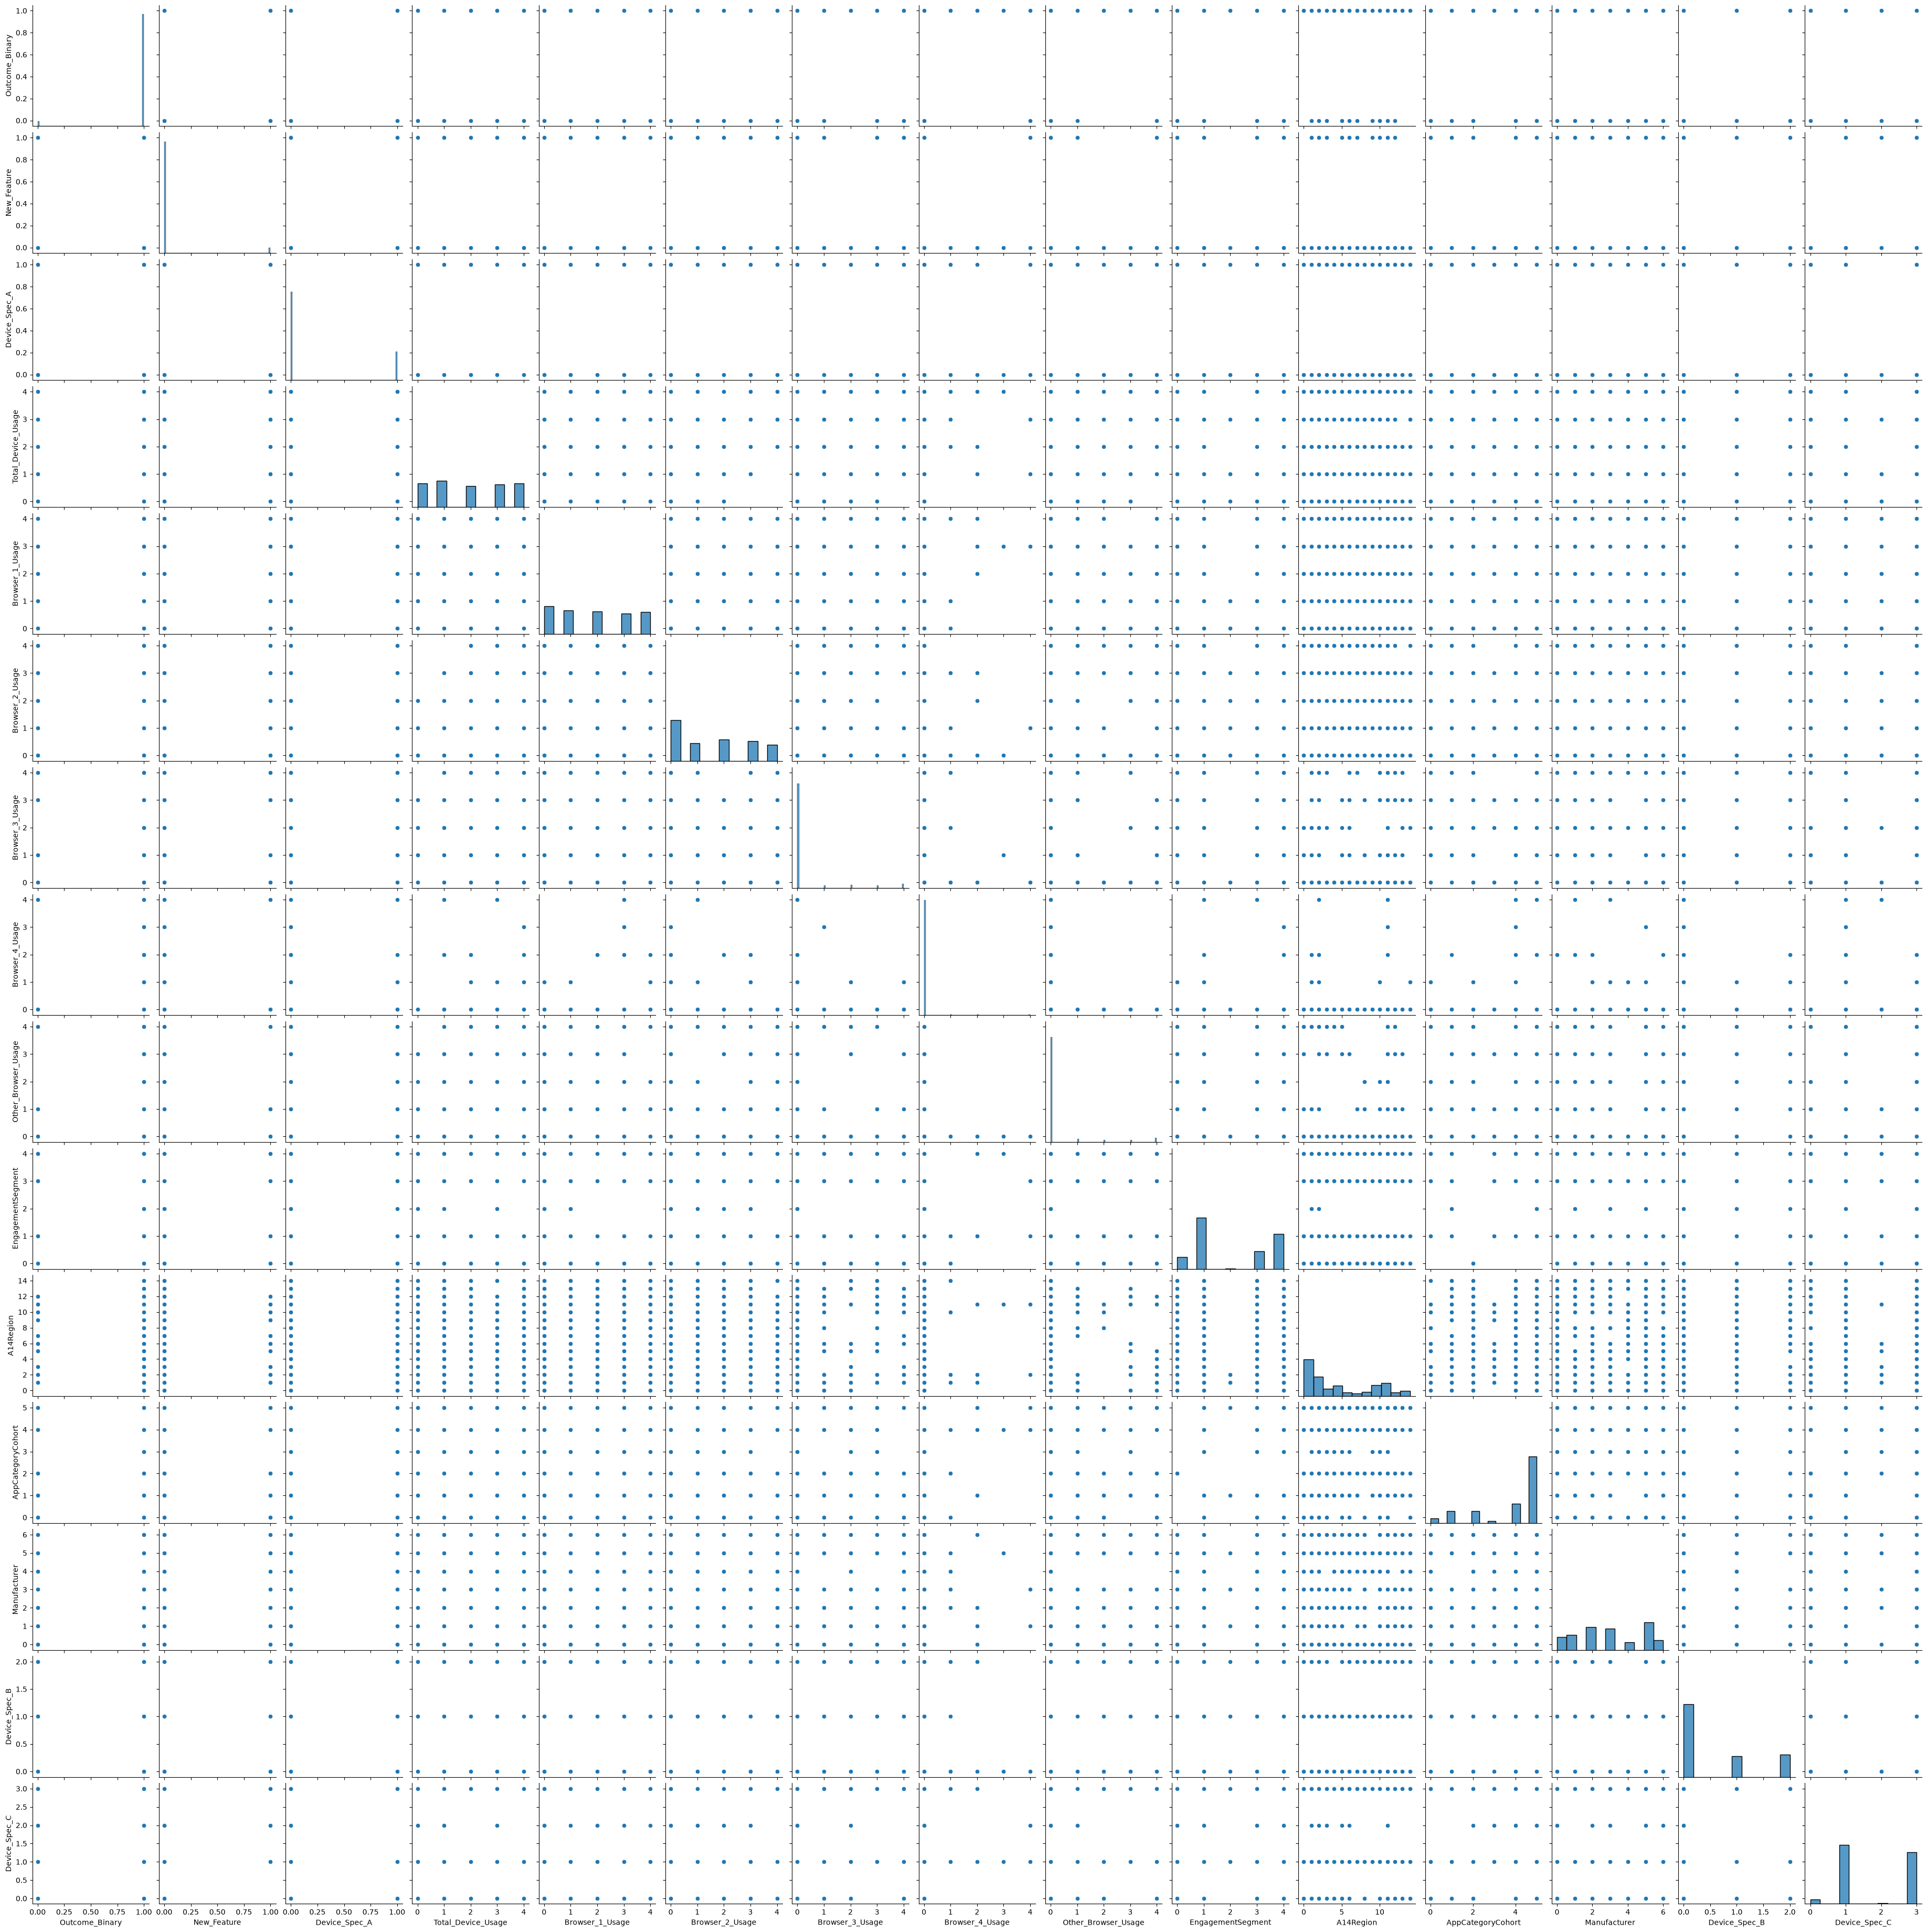

In [15]:
sns.pairplot(input_df.sample(1000))

In [9]:
def add_background_knowledge(edges):
    """Add prior edges according to assigned causal connections."""
    bk = BackgroundKnowledge()
    for edge in edges:
        node1 = GraphNode(edge['from'])
        node2 = GraphNode(edge['to'])
        bk.add_required_by_node(node1, node2)
    return bk


  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

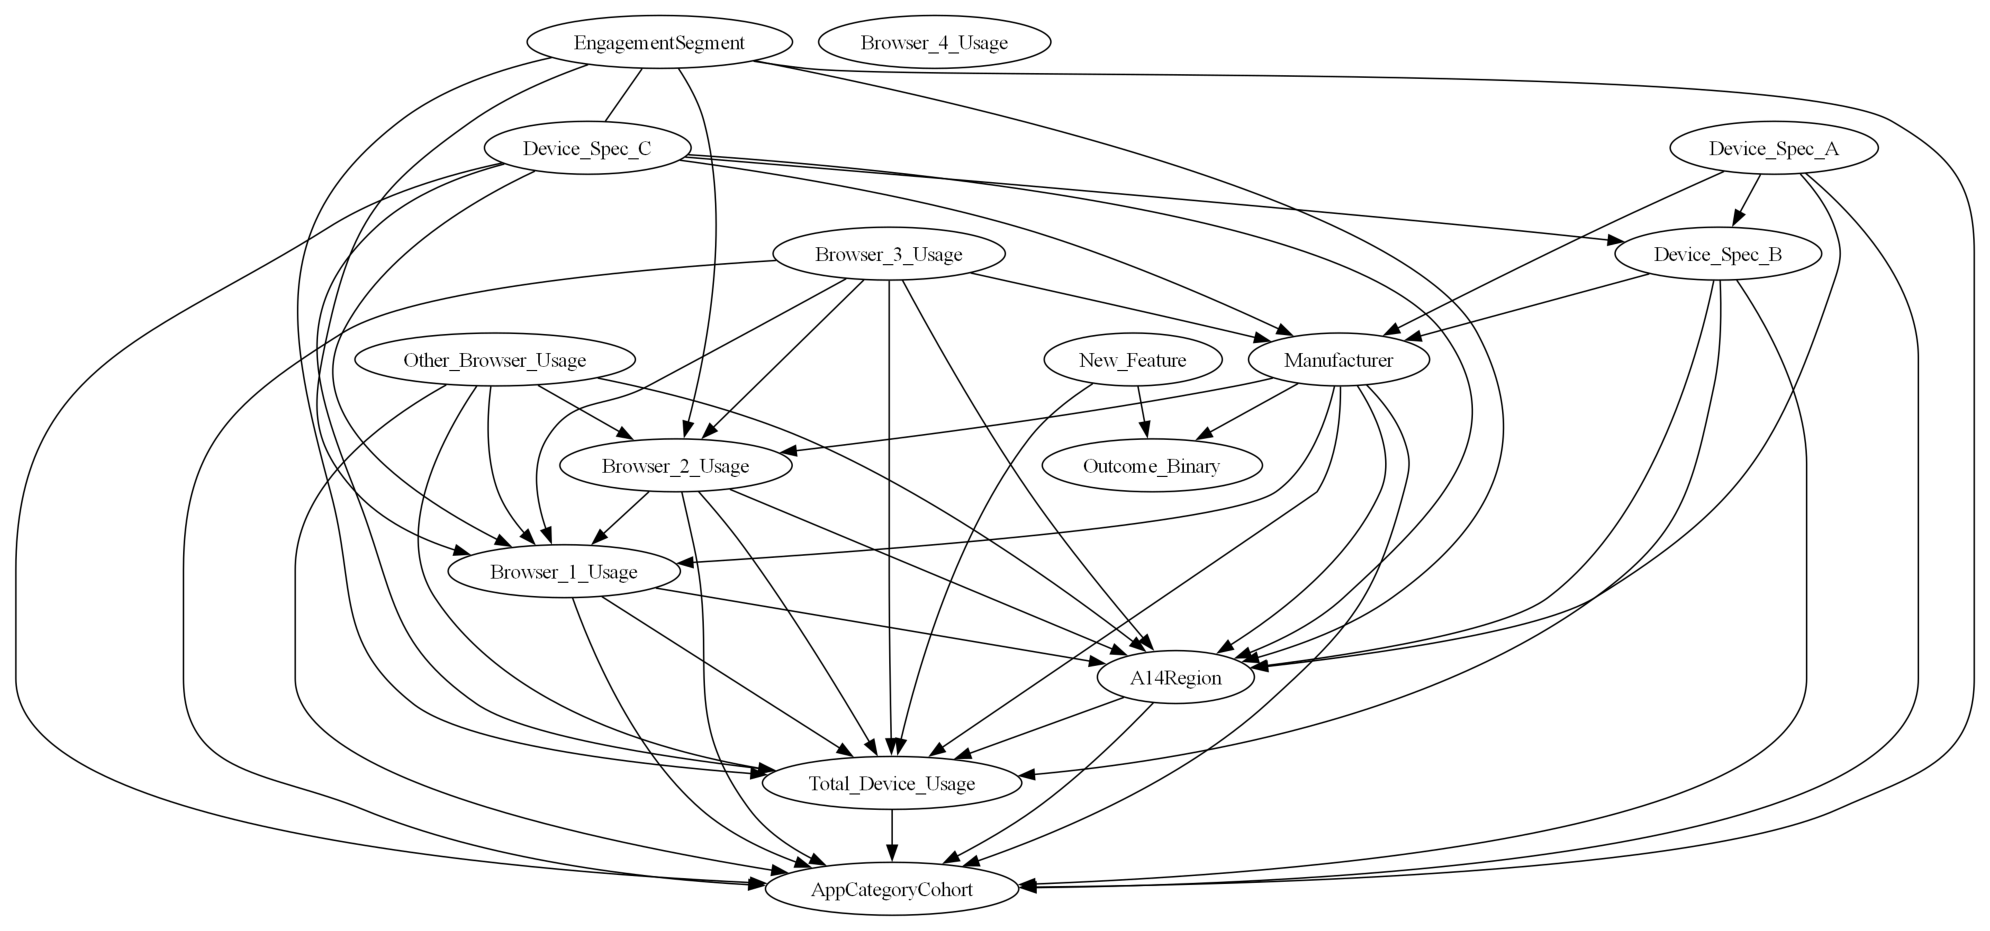

In [16]:
required_edges = [
    {"from":"Browser_1_Usage", "to":"Total_Device_Usage" },
    {"from":"Browser_2_Usage", "to":"Total_Device_Usage" },
    {"from":"Browser_3_Usage", "to":"Total_Device_Usage" },
    {"from":"Browser_4_Usage", "to":"Total_Device_Usage" },

]

background_knowledge = add_background_knowledge(
  edges = required_edges
)

# Parameters
parameters = {"node_names": input_df.columns, 
              "background_knowledge": background_knowledge, 
              "max_k": 3,
              "alpha": 0.01, 
              "indep_test": "chisq"}

rng = np.random.default_rng(0)
sub = cl_data[rng.choice(len(input_df.to_numpy()), 50000, replace=False)]
cg = pc(data=sub, **parameters)

cg = pc(data=sub, **parameters)

# Visualization using pydot
cg.draw_pydot_graph()

DISCOVERY - PYWHYLLM

In [23]:
from pywhyllm.suggesters.model_suggester import ModelSuggester
os.environ["OPENAI_API_KEY"] = openai_api_key
m = ModelSuggester('gpt-4')

In [24]:
ORIGINAL_COLS = [
    "Outcome_Binary",
    # "Outcome_Continuous",
    "New_Feature",
    "Device_Spec_A",
    "Total_Device_Usage",
    "Browser_1_Usage",
    "Browser_2_Usage",
    "Browser_3_Usage",
    "Browser_4_Usage",
    "Other_Browser_Usage",
    "EngagementSegment",
    "A14Region",
    "AppCategoryCohort",
    "Manufacturer",
    "Device_Spec_B",
    "Device_Spec_C",
]

DESCRIPTIVE_COLS = [
    "outcome_event_occurred",
    # "outcome_event_count",
    "new_feature_enabled",
    "device_capability_flag_a",
    "total_device_usage_time",
    "browser_1_usage_time",
    "browser_2_usage_time",
    "browser_3_usage_time",
    "browser_4_usage_time",
    "other_browser_usage_time",
    "user_engagement_segment",
    "user_geographic_region",
    "app_category_cohort",
    "device_manufacturer",
    "device_capability_tier_b",
    "device_capability_tier_c",
]

assert len(ORIGINAL_COLS) == len(DESCRIPTIVE_COLS), "alias lists are misaligned"
assert len(set(DESCRIPTIVE_COLS)) == len(DESCRIPTIVE_COLS), "aliases must be unique to invert"


def col_to_des_mapping(cols=input_df.columns):
    """Map input_df's column names to short descriptive aliases for pywhyllm.

    Returns the aliases in the same order as `cols`, so it drops straight into
    ModelSuggester as all_factors. Invert with des_to_col_mapping() to recover
    the original names from the suggested edges.
    """
    cols = list(cols)
    unknown = set(cols) - set(ORIGINAL_COLS)
    if unknown:
        raise KeyError(f"No alias defined for {sorted(unknown)}; extend DESCRIPTIVE_COLS.")

    col_to_des = dict(zip(ORIGINAL_COLS, DESCRIPTIVE_COLS))
    return [col_to_des[col] for col in cols]


def des_to_col_mapping():
    """Inverse lookup: descriptive alias -> original input_df column name."""
    return dict(zip(DESCRIPTIVE_COLS, ORIGINAL_COLS))


descriptive_cols = col_to_des_mapping()
des_to_col = des_to_col_mapping()

In [27]:
domain_expertises = m.suggest_domain_expertises(descriptive_cols)
domain_experts = m.suggest_domain_experts(descriptive_cols)
# parents = m.suggest_parents(domain_expertises[0], "relative_humidity", sea_ice_variables)

StitchWidget(initial_height='auto', initial_width='100%', srcdoc='<!doctype html>\n<html lang="en">\n<head>\n …

In [28]:
domain_experts

{'Data Scientist or Statistician',
 'Market Research Analyst',
 'Psychologist or Social Scientist',
 'Software Engineer or Information Systems Specialist',
 'User Experience (UX) Researcher'}

In [29]:
treatment = "new_feature_enabled"
outcome = "outcome_event_occurred"

In [30]:
"""returns a dictionary with the how many times that edge was suggested"""
model_edges = m.suggest_relationships(treatment, outcome, descriptive_cols, domain_expertises, RelationshipStrategy.Pairwise)

StitchWidget(initial_height='auto', initial_width='100%', srcdoc='<!doctype html>\n<html lang="en">\n<head>\n …

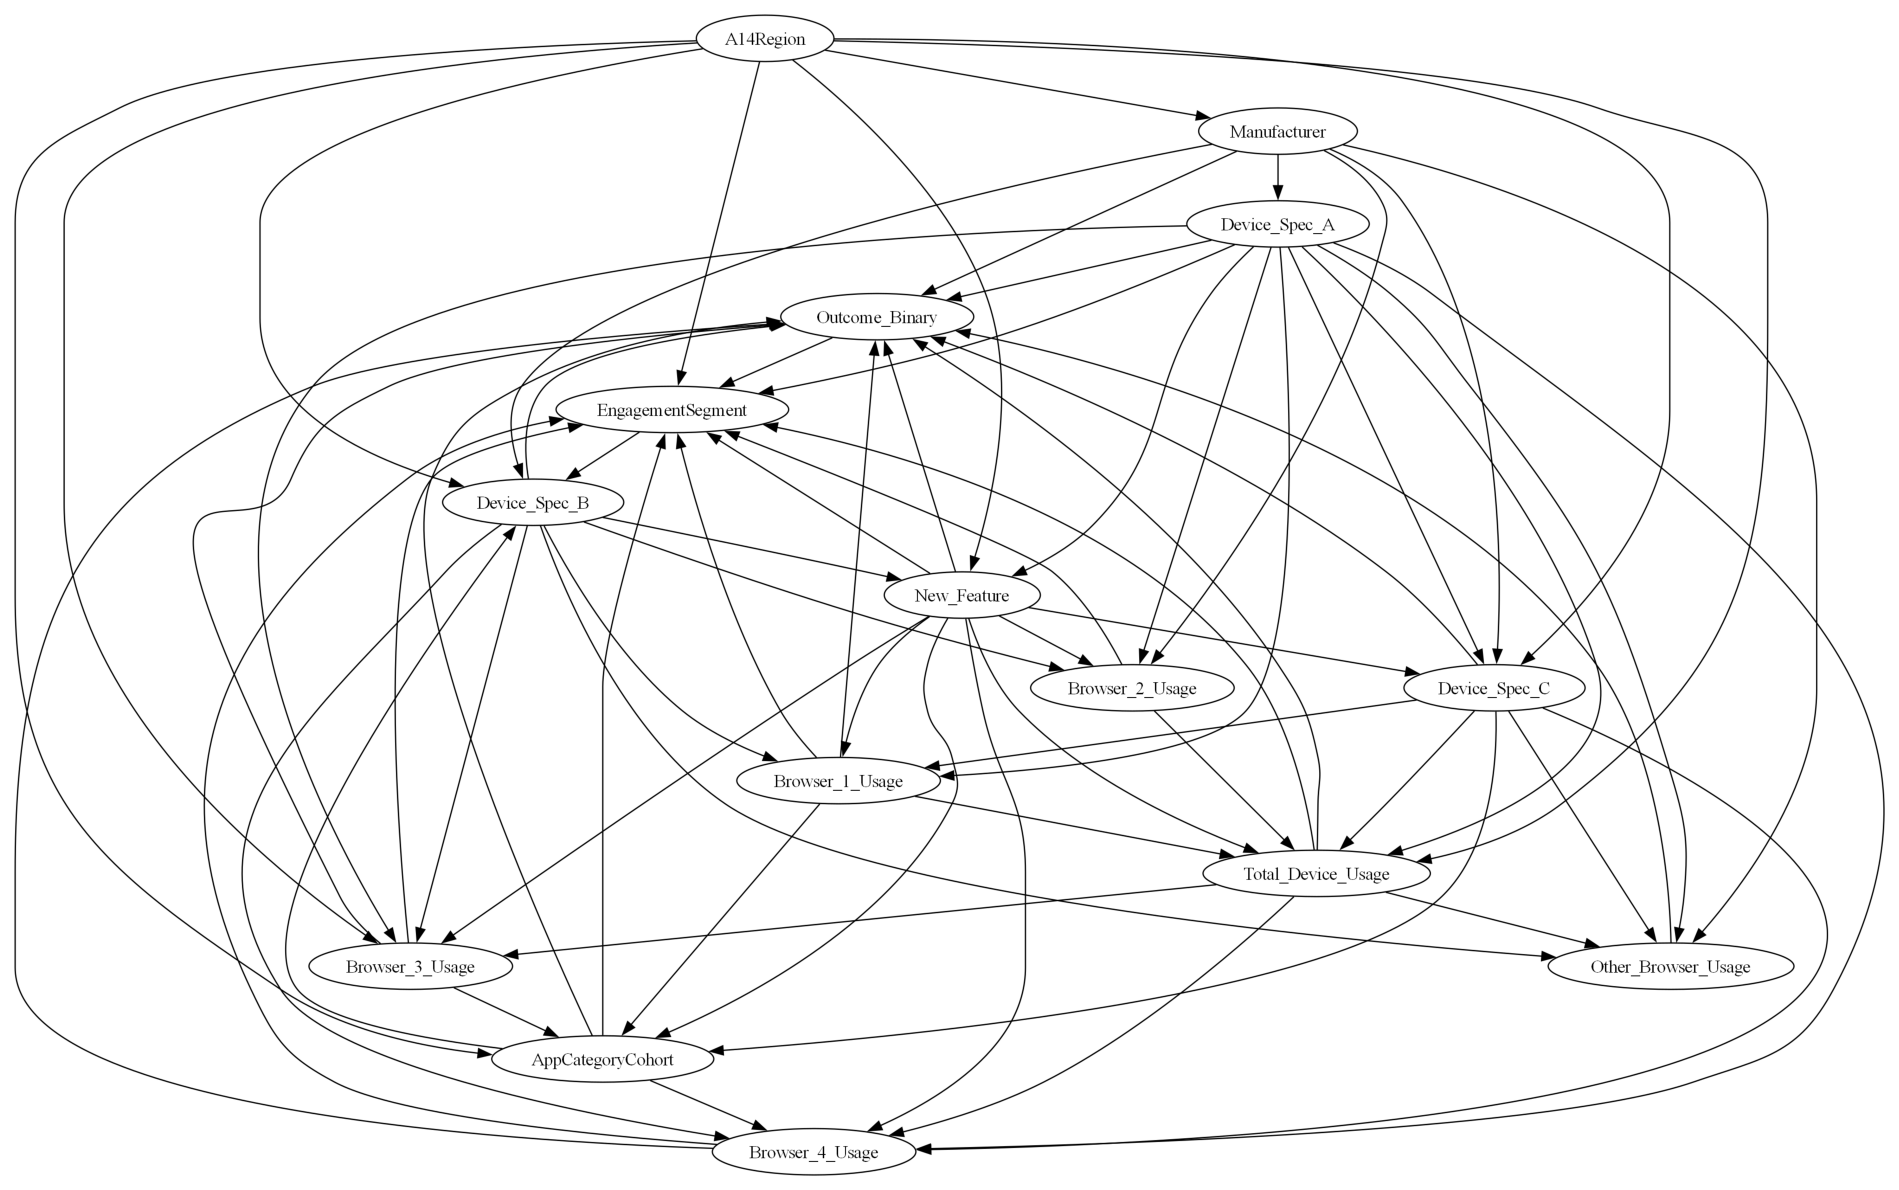

: 

In [ ]:
llm_cg = pywhyllm_edges_to_causal_graph(model_edges, node_names, name_map=des_to_col)
llm_cg.draw_pydot_graph()